In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sales = pd.read_csv("../data/processed/sales_features.csv")
customers = pd.read_csv("../data/processed/customer_features.csv")
products = pd.read_csv("../data/processed/product_features.csv")
sellers = pd.read_csv("../data/processed/seller_features.csv")
delivery = pd.read_csv("../data/processed/delivery_features.csv")
reviews = pd.read_csv("../data/processed/review_features.csv")
payments = pd.read_csv("../data/processed/payment_features.csv")

print("All feature datasets loaded successfully.")

All feature datasets loaded successfully.


In [3]:
print("Sales:", sales.shape)
print("Customers:", customers.shape)
print("Products:", products.shape)
print("Sellers:", sellers.shape)
print("Delivery:", delivery.shape)
print("Reviews:", reviews.shape)
print("Payments:", payments.shape)

Sales: (112650, 35)
Customers: (98666, 8)
Products: (32951, 6)
Sellers: (3095, 6)
Delivery: (113425, 23)
Reviews: (99441, 3)
Payments: (99441, 4)


In [4]:
total_revenue = sales["item_revenue"].sum()
total_orders = sales["order_id"].nunique()
total_customers = sales["customer_id"].nunique()

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)

Total Revenue: 13591643.7
Total Orders: 98666
Total Customers: 98666


In [5]:
sales["order_purchase_timestamp"] = pd.to_datetime(
    sales["order_purchase_timestamp"],
    errors="coerce"
)

monthly_revenue = (
    sales.groupby(
        sales["order_purchase_timestamp"].dt.to_period("M")
    )["item_revenue"]
    .sum()
)

monthly_revenue.index = monthly_revenue.index.astype(str)

display(monthly_revenue)

order_purchase_timestamp
2016-09        267.36
2016-10      49507.66
2016-12         10.90
2017-01     120312.87
2017-02     247303.02
2017-03     374344.30
2017-04     359927.23
2017-05     506071.14
2017-06     433038.60
2017-07     498031.48
2017-08     573971.68
2017-09     624401.69
2017-10     664219.43
2017-11    1010271.37
2017-12     743914.17
2018-01     950030.36
2018-02     844178.71
2018-03     983213.44
2018-04     996647.75
2018-05     996517.68
2018-06     865124.31
2018-07     895507.22
2018-08     854686.33
2018-09        145.00
Name: item_revenue, dtype: float64

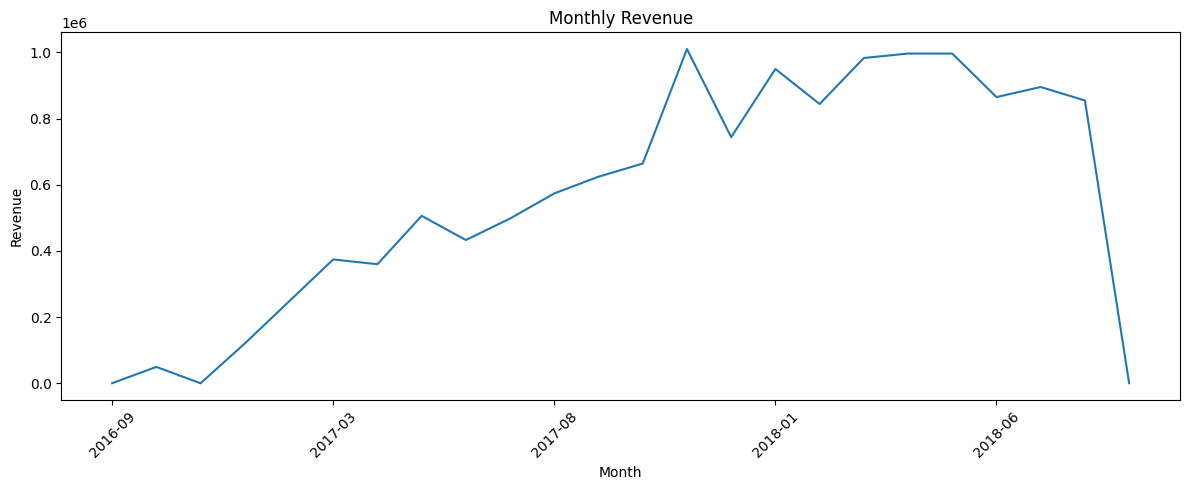

In [6]:
plt.figure(figsize=(12, 5))

monthly_revenue.plot()

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
monthly_orders = (
    sales.groupby(
        sales["order_purchase_timestamp"].dt.to_period("M")
    )["order_id"]
    .nunique()
)

monthly_orders.index = monthly_orders.index.astype(str)

display(monthly_orders)

order_purchase_timestamp
2016-09       3
2016-10     308
2016-12       1
2017-01     789
2017-02    1733
2017-03    2641
2017-04    2391
2017-05    3660
2017-06    3217
2017-07    3969
2017-08    4293
2017-09    4243
2017-10    4568
2017-11    7451
2017-12    5624
2018-01    7220
2018-02    6694
2018-03    7188
2018-04    6934
2018-05    6853
2018-06    6160
2018-07    6273
2018-08    6452
2018-09       1
Name: order_id, dtype: int64

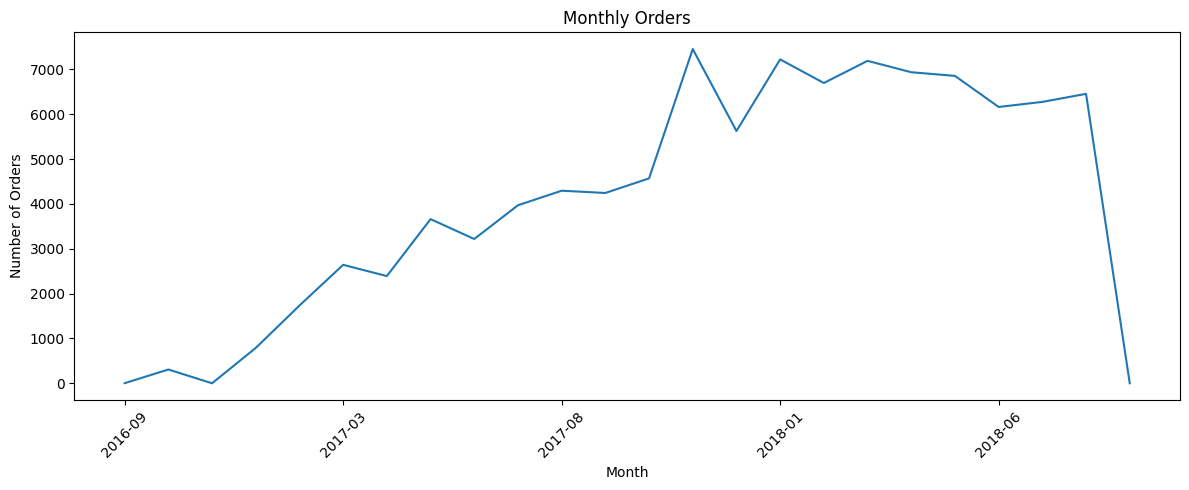

In [8]:
plt.figure(figsize=(12, 5))

monthly_orders.plot()

plt.title("Monthly Orders")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
top_categories = (
    sales.groupby("product_category_name")["item_revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_categories)

product_category_name
beleza_saude              1258681.34
relogios_presentes        1205005.68
cama_mesa_banho           1036988.68
esporte_lazer              988048.97
informatica_acessorios     911954.32
moveis_decoracao           729762.49
cool_stuff                 635290.85
utilidades_domesticas      632248.66
automotivo                 592720.11
ferramentas_jardim         485256.46
Name: item_revenue, dtype: float64

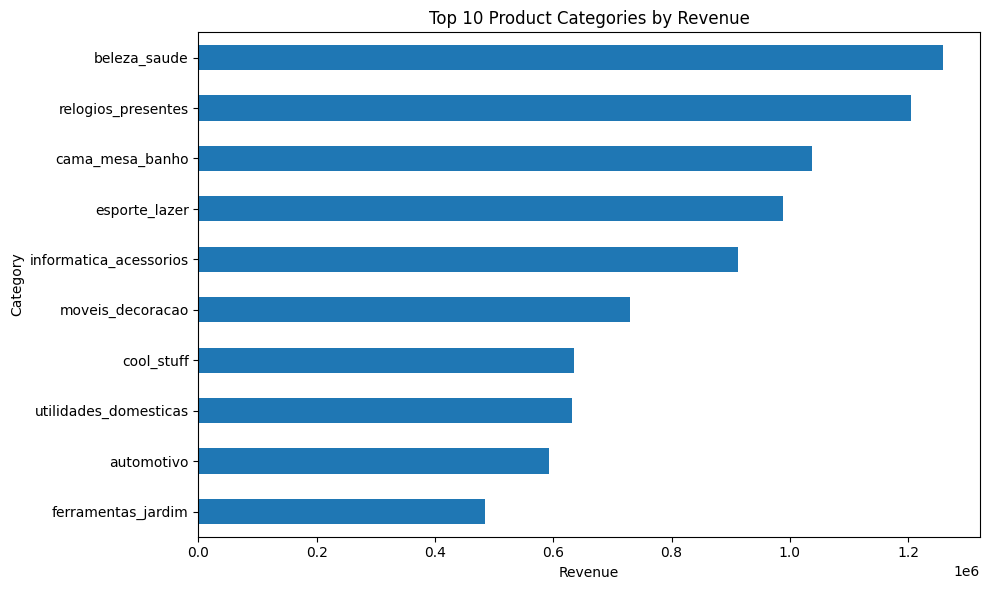

In [10]:
plt.figure(figsize=(10, 6))

top_categories.sort_values().plot(kind="barh")

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [12]:
print("Average Customer Spending:",
      round(customers["total_spending"].mean(), 2))

print("Maximum Customer Spending:",
      round(customers["total_spending"].max(), 2))

print("Average Orders per Customer:",
      round(customers["total_orders"].mean(), 2))

Average Customer Spending: 160.58
Maximum Customer Spending: 13664.08
Average Orders per Customer: 1.0


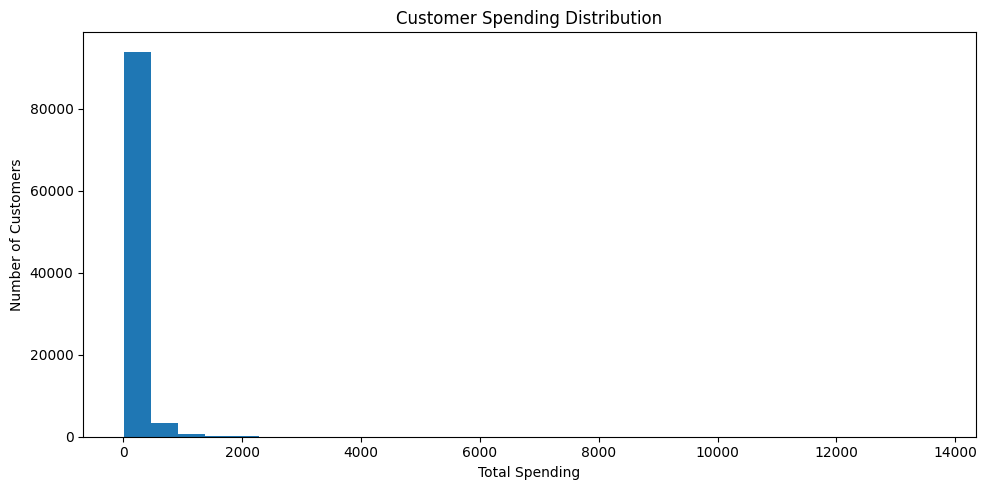

In [13]:
plt.figure(figsize=(10, 5))

plt.hist(
    customers["total_spending"],
    bins=30
)

plt.title("Customer Spending Distribution")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [14]:
frequency_counts = (
    customers["total_orders"]
    .value_counts()
    .sort_index()
    .head(15)
)

display(frequency_counts)

total_orders
1    98666
Name: count, dtype: int64

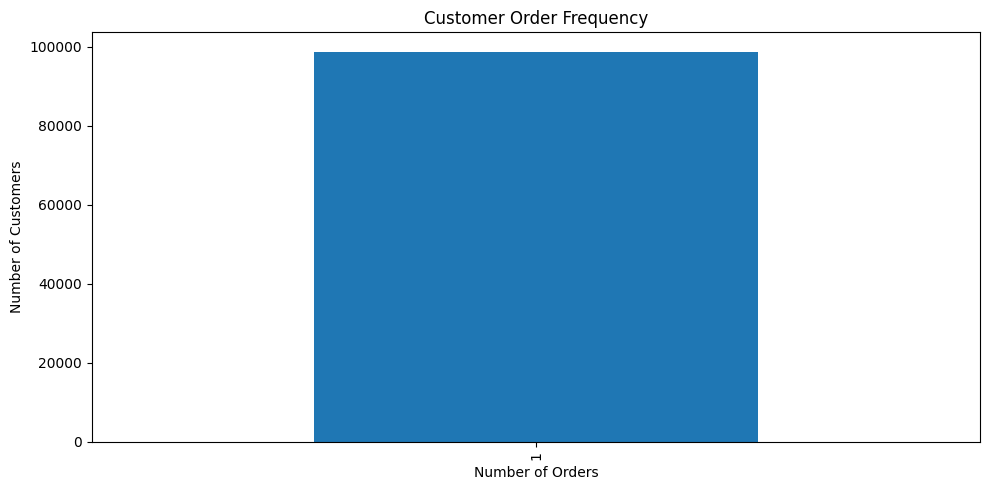

In [15]:
plt.figure(figsize=(10, 5))

frequency_counts.plot(kind="bar")

plt.title("Customer Order Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [16]:
top_sellers = (
    sellers.sort_values(
        "seller_revenue",
        ascending=False
    )
    .head(10)
)

display(
    top_sellers[
        [
            "seller_id",
            "seller_orders",
            "seller_revenue",
            "seller_items"
        ]
    ]
)

,seller_id,seller_orders,seller_revenue,seller_items
857,4869f7a5dfa277a7dca6462dcf3b52b2,1132,229472.63,1156
1013,53243585a1d6dc2643021fd1853d8905,358,222776.05,410
881,4a3ca9315b744ce9f8e9374361493884,1806,200472.92,1987
3024,fa1c13f2614d7b5c4749cbc52fecda94,585,194042.03,586
1535,7c67e1448b00f6e969d365cea6b010ab,982,187923.89,1364
1560,7e93a43ef30c4f03f38b393420bc753a,336,176431.87,340
2643,da8622b14eb17ae2831f4ac5b9dab84a,1314,160236.57,1551
1505,7a67c85e85bb2ce8582c35f2203ad736,1160,141745.53,1171
192,1025f0e2d44d7041d6cf58b6550e0bfa,915,138968.55,1428
1824,955fee9216a65b617aa5c0531780ce60,1287,135171.70,1499


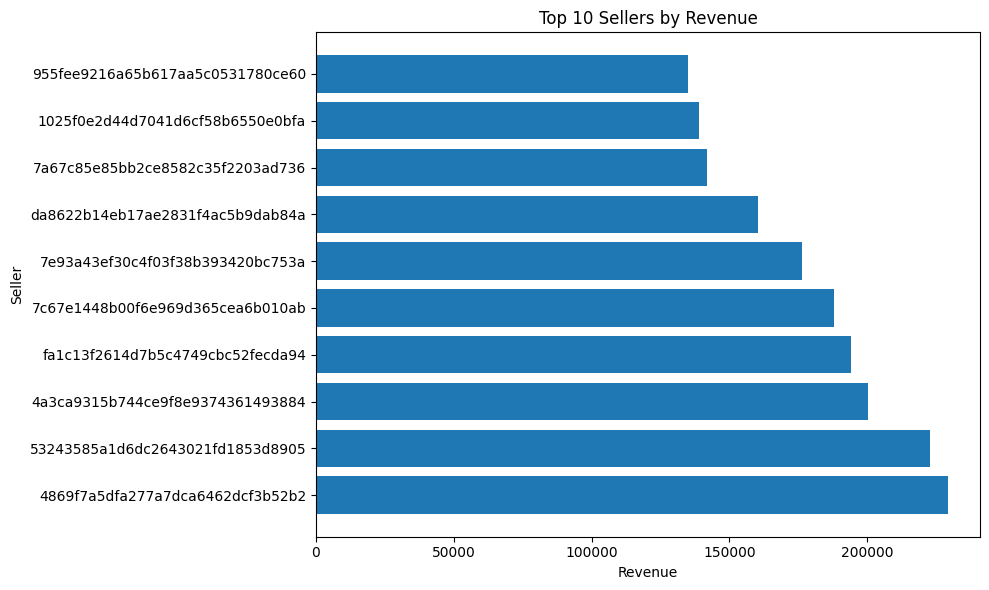

In [17]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_sellers["seller_id"].astype(str),
    top_sellers["seller_revenue"]
)

plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Seller")
plt.tight_layout()
plt.show()

In [18]:
print(
    "Average Delivery Days:",
    round(delivery["delivery_days"].mean(), 2)
)

print(
    "Average Delay Days:",
    round(delivery["delivery_delay_days"].mean(), 2)
)

print(
    "On-Time Delivery Percentage:",
    round(delivery["on_time_flag"].mean() * 100, 2),
    "%"
)

Average Delivery Days: 12.01
Average Delay Days: -12.03
On-Time Delivery Percentage: 90.75 %


In [19]:
delivery_status = delivery["on_time_flag"].value_counts()

delivery_status.index = [
    "On Time" if x == 1 else "Delayed"
    for x in delivery_status.index
]

display(delivery_status)

On Time    102931
Delayed     10494
Name: count, dtype: int64

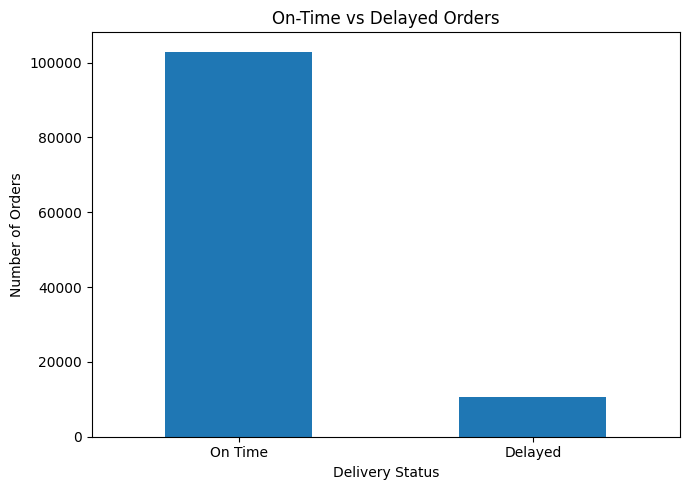

In [20]:
plt.figure(figsize=(7, 5))

delivery_status.plot(kind="bar")

plt.title("On-Time vs Delayed Orders")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
review_distribution = (
    reviews["average_review_score"]
    .round()
    .value_counts()
    .sort_index()
)

display(review_distribution)

average_review_score
1.0    11316
2.0     3167
3.0     8137
4.0    19098
5.0    56955
Name: count, dtype: int64

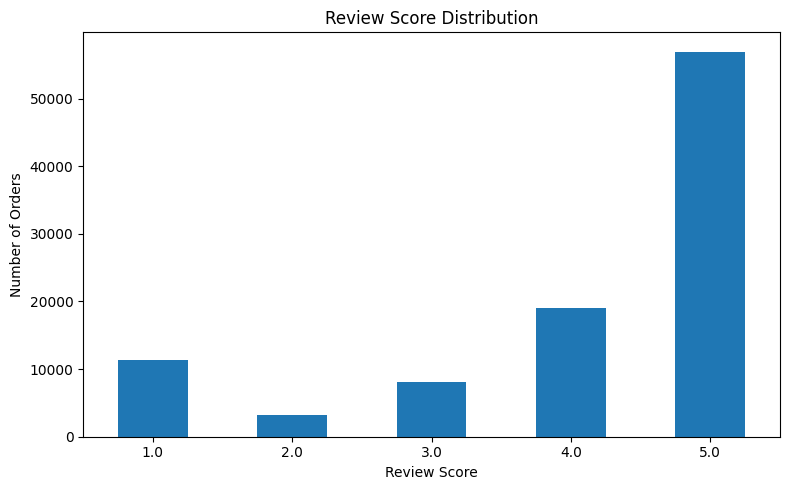

In [22]:
plt.figure(figsize=(8, 5))

review_distribution.plot(kind="bar")

plt.title("Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
delivery_review = delivery[
    [
        "order_id",
        "delivery_days",
        "delivery_delay_days",
        "on_time_flag"
    ]
].merge(
    reviews[
        [
            "order_id",
            "average_review_score"
        ]
    ],
    on="order_id",
    how="inner"
)

display(delivery_review.head())

,order_id,delivery_days,delivery_delay_days,on_time_flag,average_review_score
0,e481f51cbdc54678b7cc49136f2d6af7,8.0,-8.0,1,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,13.0,-6.0,1,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,9.0,-18.0,1,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,13.0,-13.0,1,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2.0,-10.0,1,5.0


In [24]:
delay_review = (
    delivery_review
    .groupby("on_time_flag")["average_review_score"]
    .mean()
)

delay_review.index = [
    "Delayed" if x == 0 else "On Time"
    for x in delay_review.index
]

display(delay_review)

Delayed    2.101533
On Time    4.208268
Name: average_review_score, dtype: float64

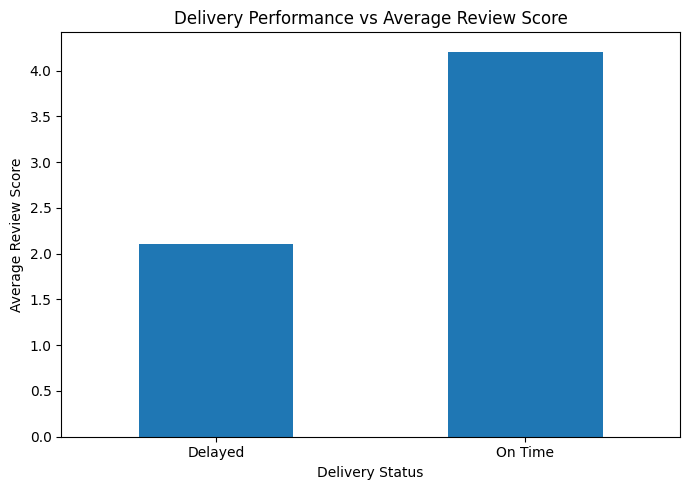

In [25]:
plt.figure(figsize=(7, 5))

delay_review.plot(kind="bar")

plt.title("Delivery Performance vs Average Review Score")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [26]:
payment_methods = (
    payments["payment_methods"]
    .value_counts()
    .sort_index()
)

display(payment_methods)

payment_methods
0        1
1    97194
2     2246
Name: count, dtype: int64

In [27]:
print(
    "Total Payment Value:",
    round(payments["total_payment"].sum(), 2)
)

print(
    "Average Payment Value:",
    round(payments["total_payment"].mean(), 2)
)

Total Payment Value: 16008872.12
Average Payment Value: 160.99


In [28]:
average_order_value = (
    sales.groupby("order_id")["total_item_value"]
    .sum()
    .mean()
)

average_delivery_days = delivery["delivery_days"].mean()

average_review_score = reviews["average_review_score"].mean()

on_time_percentage = delivery["on_time_flag"].mean() * 100

print("===== Commerce360 KPIs =====")
print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Order Value:", round(average_order_value, 2))
print("Average Delivery Days:", round(average_delivery_days, 2))
print("On-Time Delivery:", round(on_time_percentage, 2), "%")
print("Average Review Score:", round(average_review_score, 2))

===== Commerce360 KPIs =====
Total Revenue: 13591643.7
Total Orders: 98666
Total Customers: 98666
Average Order Value: 160.58
Average Delivery Days: 12.01
On-Time Delivery: 90.75 %
Average Review Score: 4.09


In [29]:
print("EDA completed successfully.")
print()
print("Key areas analyzed:")
print("1. Sales and revenue")
print("2. Monthly orders")
print("3. Product categories")
print("4. Top products")
print("5. Customer behavior")
print("6. Seller performance")
print("7. Delivery performance")
print("8. Review scores")
print("9. Delivery vs review relationship")
print("10. Payment analysis")

EDA completed successfully.

Key areas analyzed:
1. Sales and revenue
2. Monthly orders
3. Product categories
4. Top products
5. Customer behavior
6. Seller performance
7. Delivery performance
8. Review scores
9. Delivery vs review relationship
10. Payment analysis
